In [98]:
#Mathematics and ML
import torch
import ot
import random

#Plotting
import matplotlib.pyplot as plt

#Project package
from graphtools import graphon, metrics, opt

#Autoreload module
"""
These magic lines allow to automatically reload any module.py file when there are some changes on it, without the needing of restart the kernel anytime a new change is applied to the module script
"""
%load_ext autoreload
%autoreload 2

# Creation functions need an explicit target device. Metrics will infer it from the graph.
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# **Fused Gromov-Wasserstein (FGW):**
Distance between two graphs $\mathcal{G}_1 = (X_1, C_1, n_1), \, \mathcal{G}_2 = (X_2, C_2, n_2)$ simultaneously taking into account structural and node state features:

$$
FGW_{q, \alpha} = \operatorname*{min}_{\Pi} [ (1-\alpha) \underbrace{\langle M(X_1, X_2)^q, \Pi \rangle}_{\substack{\text{Wasserstein} \\ \text{node feature loss term}}} + \alpha \underbrace{\langle L(C_1, C_2)^q \otimes \Pi, \Pi \rangle}_{\substack{ \text{Gromov-Wasserstein} \\ \text{structural loss term}}} ]
$$
Where:
$$\underbrace{M(X_1, X_2)^q_{ij} = d(x_1^i, x_2^j)^q}_{\text{Node feature descrepancy}} \in \mathbb{R}^{n_1 \times n_2}, \qquad \underbrace{L(C_1, C_2)^q_{ijkl} = |C_1^{ik} - C_2^{jl}|^q}_{\text{Pairwise structure descrepancy}} \in \mathbb{R}^{n_1 \times n_2 \times n_1 \times n_2}$$

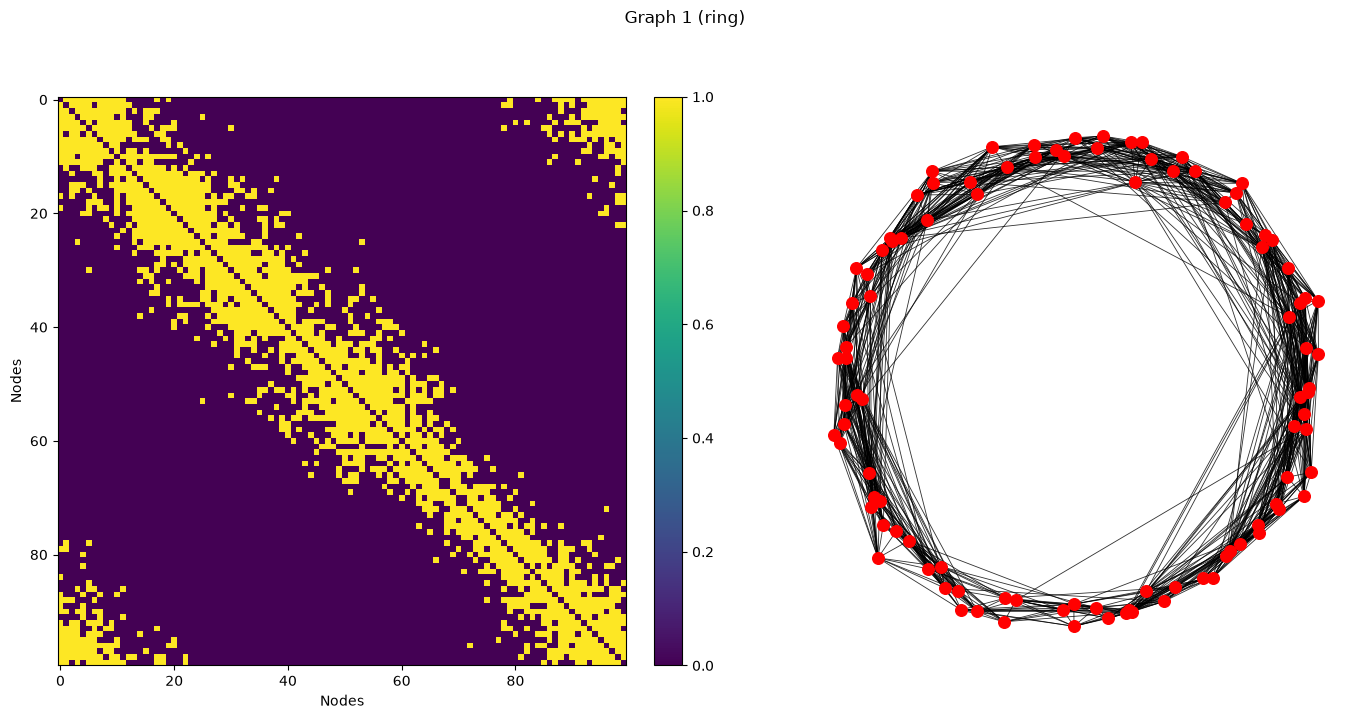

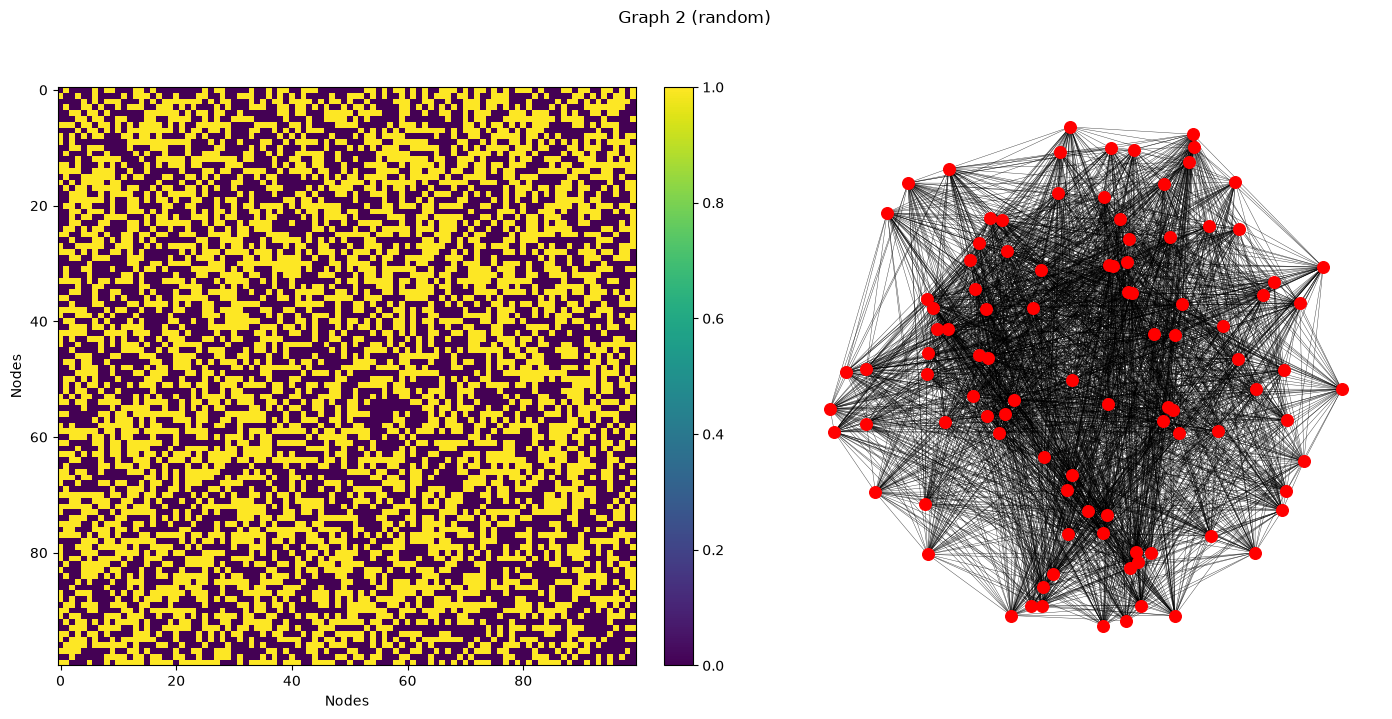

In [2]:
# Create inital graphs
types = [
    ("ring", "ring"),
    ("random", "circle"),
]

n = [100, 100]
state = "continuous"
hist = "degree" #Type of graph histogram
if state == "continuous":
    state_kwargs = {"d" : 3}

graphs = [graphon.sample_graph(n = n[i], structure = combination[0], positions = combination[1], state = state, state_kwargs = state_kwargs, device = device) 
          for i, combination in enumerate(types)]
if hist == "degree":
    for graph in graphs:
        tot_degree = metrics.adjacency_matrix(graph, normalized = False, sparse = False).sum()
        degrees = metrics.adjacency_matrix(graph, normalized = False, sparse = False).sum(dim = 0)
        graph.h = degrees / tot_degree
        

for i, graph in enumerate(graphs):
    graphon.plot_graph(graph, title = f"Graph {i + 1} ({types[i][0]})")

In [ ]:
# Compute FGW loss
loss, info = opt.fused_gromov_wasserstein_distance(graphs[0], graphs[1])
print(f"FGW loss: {loss}")
print(f"Wasserstein term: {info['w_term']}")
print(f"Gromov-Wasserstein term: {info['gw_term']}")

FGW loss: 0.581175684928894
Wasserstein term: 0.34159207344055176
Gromov-Wasserstein term: 0.23958361148834229


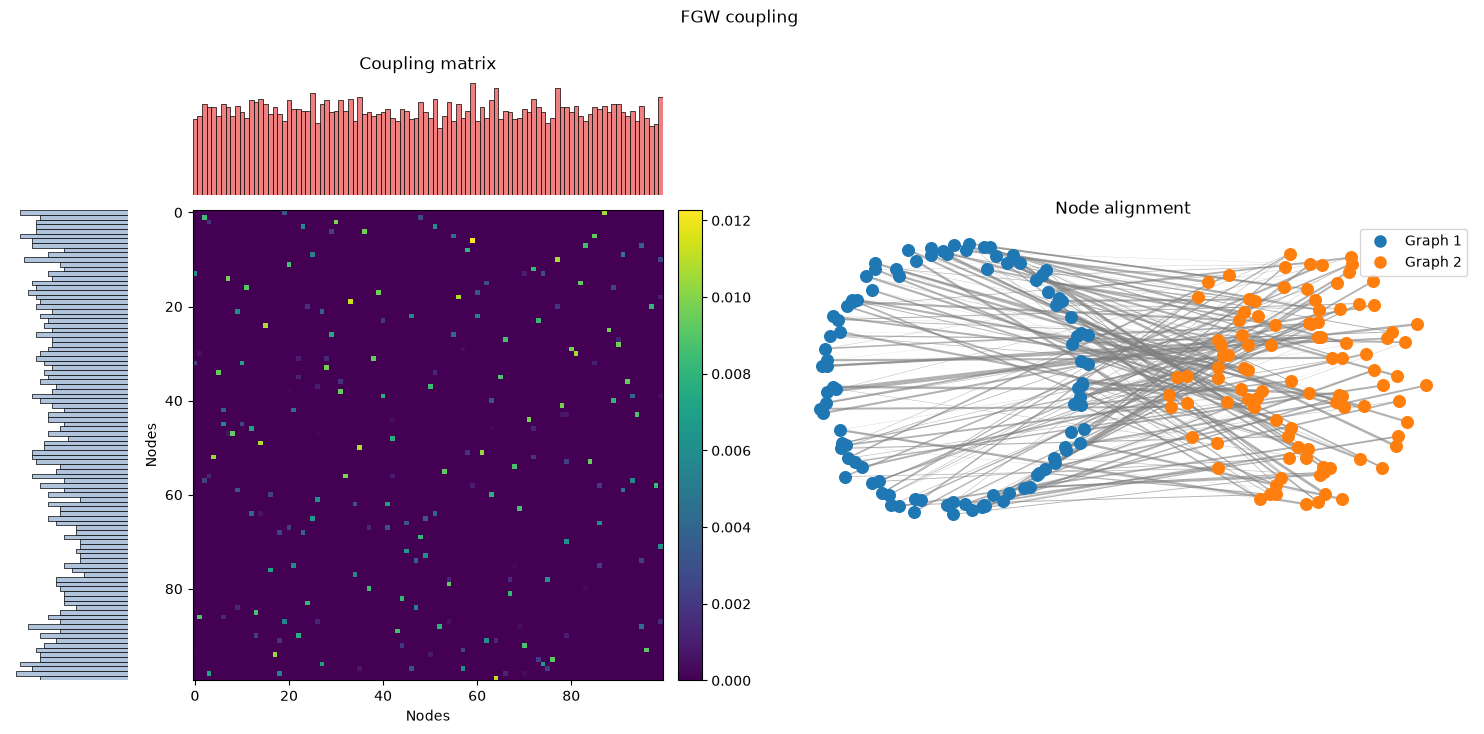

In [ ]:
# Plot FGW node coupling
coupling = info["T"]
opt.plot_coupling(graphs[0], graphs[1], coupling, show_marginals = True, title = "FGW coupling")

## **Gromov-Wasserstein component:**

In [5]:
# Create inital graphs
types = [
    ("ring", "ring"),
    ("sbm", "bubbles"),
    ("random", "circle"),
]

n = 100
hist = "degree" #Type of graph histogram
examples = 50 #Graphs to generate for each type
graphs = {}

# Multiple examples for every structural group
for kind, pos in types:
    graphs_type = [None] * examples
    for i in range(examples):
        graph = graphon.sample_graph(n = n, structure = kind, positions = pos, device = device)
        if hist == "degree":
            tot_degree = metrics.adjacency_matrix(graph, normalized = False, sparse = False).sum()
            degrees = metrics.adjacency_matrix(graph, normalized = False, sparse = False).sum(dim = 0)
            graph.h = degrees / tot_degree
        graphs_type[i] = graph
    graphs[kind] = graphs_type

In [ ]:
# Compare random graph pairs for every combination of sizes.
values = {}
alpha = 1
comparisons = 50

for type_1, graphs_1 in graphs.items():
    distances_by_type = []
    for type_2, graphs_2 in graphs.items():
        distances = []
        for _ in range(comparisons):
            if type_1 == type_2:
                graph_1, graph_2 = random.sample(graphs_1, 2)
            else:
                graph_1 = random.choice(graphs_1)
                graph_2 = random.choice(graphs_2)
            distance, _ = opt.fused_gromov_wasserstein_distance(graph_1, graph_2, alpha = alpha)
            distances.append(distance)
        distances_by_type.append(torch.stack(distances))
    # Rows follow the order of the type groups in graphs.
    values[type_1] = torch.stack(distances_by_type)

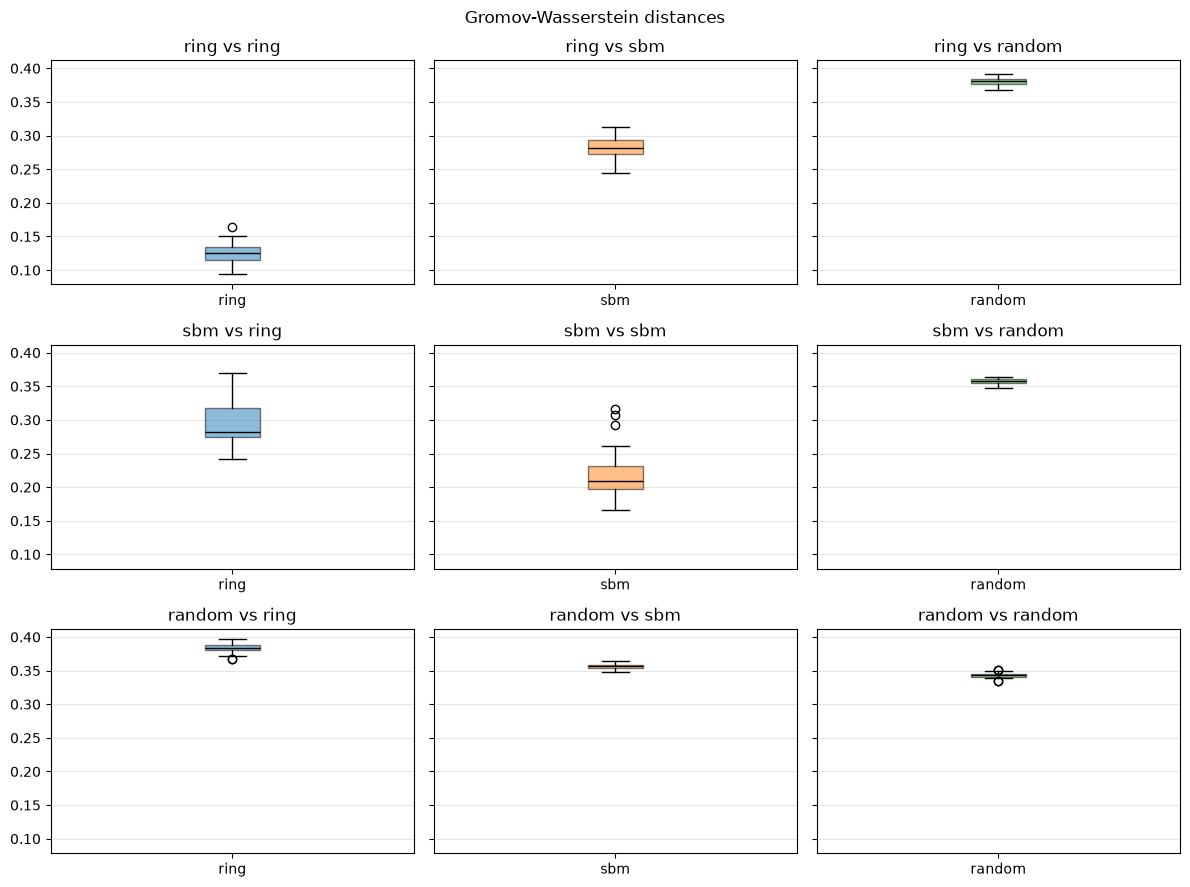

In [7]:
# Box plots: rows are representatives, columns are compared graph structures.
n_types = len(values)
graph_types = list(graphs)
fig, axes = plt.subplots(n_types, n_types, figsize = (4 * n_types, 3 * n_types),
                         sharey = True, squeeze = False)
colors = plt.get_cmap("tab10")

for i, (reference_kind, distances) in enumerate(values.items()):
    for j, graph_kind in enumerate(graph_types):
        ax = axes[i, j]
        box = ax.boxplot(distances[j].detach().cpu().numpy(), patch_artist = True,
                         medianprops = {"color": "black"})
        box["boxes"][0].set_facecolor(colors(j % colors.N))
        box["boxes"][0].set_alpha(0.5)
        ax.set_title(f"{reference_kind} vs {graph_kind}")
        ax.set_xticks([1], [graph_kind])
        ax.grid(axis = "y", alpha = 0.3)

fig.suptitle("Gromov-Wasserstein distances")
fig.tight_layout()
plt.show()

## **Impact of varying graph size**

In [8]:
# Create inital graphs

sizes = [50, 100, 500]
kind = "ring"
pos = "ring"
hist = "degree" #Type of graph histogram
state = "continuous"
if state == "continuous":
    state_kwargs = {"d" : 3}
examples = 1000 #Graphs to generate for each type
graphs = {}

# Multiple examples for every structural group
for n in sizes:
    graphs_type = [None] * examples
    for i in range(examples):
        if state == "continuous":
            graph = graphon.sample_graph(n = n, structure = kind, positions = pos, device = device, state = state, state_kwargs = state_kwargs)
        else:
            graph = graphon.sample_graph(n = n, structure = kind, positions = pos, device = device)
        if hist == "degree":
            tot_degree = metrics.adjacency_matrix(graph, normalized = False, sparse = False).sum()
            degrees = metrics.adjacency_matrix(graph, normalized = False, sparse = False).sum(dim = 0)
            graph.h = degrees / tot_degree
        graphs_type[i] = graph
    graphs[str(n)] = graphs_type

In [ ]:
# Compare random graph pairs for every combination of sizes
values = {}
alpha = 1
comparisons = 50

for n_1, graphs_1 in graphs.items():
    distances_by_size = []
    for n_2, graphs_2 in graphs.items():
        distances = []
        for _ in range(comparisons):
            if n_1 == n_2:
                graph_1, graph_2 = random.sample(graphs_1, 2)
            else:
                graph_1 = random.choice(graphs_1)
                graph_2 = random.choice(graphs_2)
            distance, _ = opt.fused_gromov_wasserstein_distance(graph_1, graph_2, alpha = alpha)
            distances.append(distance)
        distances_by_size.append(torch.stack(distances))
    # Rows follow the order of the size groups in graphs.
    values[int(n_1)] = torch.stack(distances_by_size)

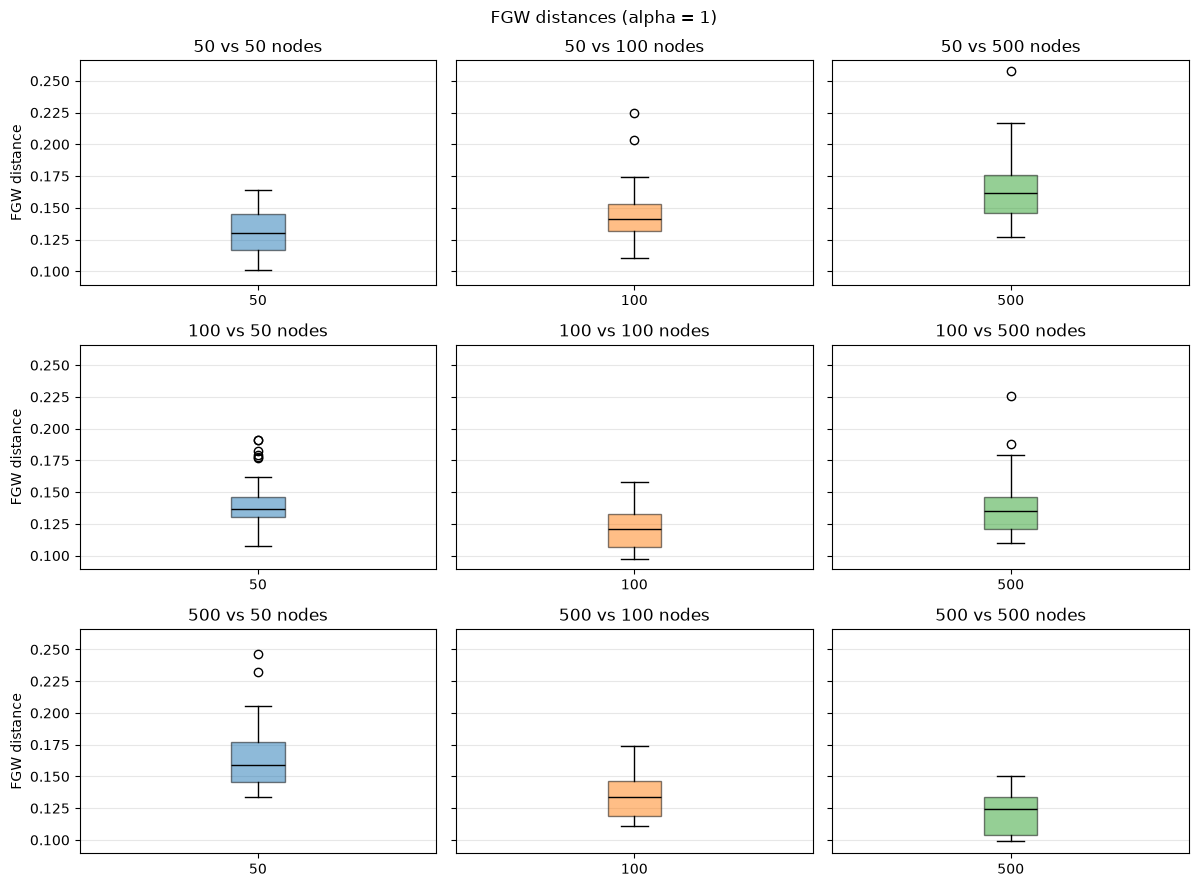

In [10]:
# Plot distance distributions for every pair of graph sizes
n_sizes = len(values)
graph_sizes = list(graphs)
fig, axes = plt.subplots(n_sizes, n_sizes, figsize = (4 * n_sizes, 3 * n_sizes),
                         sharey = True, squeeze = False)
colors = plt.get_cmap("tab10")

for i, (n_1, distances) in enumerate(values.items()):
    for j, n_2 in enumerate(graph_sizes):
        ax = axes[i, j]
        box = ax.boxplot(distances[j].detach().cpu().numpy(), patch_artist = True,
                         medianprops = {"color": "black"})
        box["boxes"][0].set_facecolor(colors(j % colors.N))
        box["boxes"][0].set_alpha(0.5)
        ax.set_title(f"{n_1} vs {n_2} nodes")
        ax.set_xticks([1], [str(n_2)])
        ax.grid(axis = "y", alpha = 0.3)
        if j == 0:
            ax.set_ylabel("FGW distance")

fig.suptitle(f"FGW distances (alpha = {alpha})")
fig.tight_layout()
plt.show()

# **OT empirical coupling:**
Given two graph's distributions $P$ and $Q$, we extract K-dimensional batches from them as $\mathbf{x} = \{x_i\}_i \overset{iid}{\sim} P, \mathbf{y} = \{y_j\}_j \overset{iid}{\sim} Q$, inducing the empirical marginal distributions:

$$P^{(K)}(x) = \frac{1}{K}\sum_i \delta(x-x_i), \qquad Q^{(K)}(y) = \frac{1}{K}\sum_j \delta(y-y_j)$$

A coupling between $P^{(K)}$ and $Q^{(K)}$ is defined in terms of a doubly stochastic matrix $W \in \mathbb{R}^{K \times K}$ satisfying conditions $\sum_i w_{ij} = \sum_j w_{ij} = \frac{1}{K}$. Thus, finding an empirical optimal coupling between $P$ and $Q$ means solving the following optimization problem:

$$\operatorname*{min}_{W} \left[ \sum_{ij} w_{ij} c(x_i, x_j)\right] = \operatorname*{min}_{W} \left[ \langle W, C\rangle_F \right]$$

In [104]:
# Sample empirical batches
K = 100 # Batch size
sizes = [100, 200] # Graph sizes for the two batches

types = [
    ("ring", "ring"),
    ("ring", "ring"),
]

state = "continuous"
hist = "degree" #Type of graph histogram
if state == "continuous":
    state_kwargs = {"d" : 3}

batches = {}
for i, combination in enumerate(types):
    graphs = []
    for _ in range(K):
        graph = graphon.sample_graph(n = sizes[i], structure = combination[0], positions = combination[1], state = state, state_kwargs = state_kwargs, device = device)
        adjacency = metrics.adjacency_matrix(graph, normalized = False, sparse = False)
        graph.C = adjacency
        if hist == "degree":
            tot_degree = adjacency.sum()
            degrees = adjacency.sum(dim = 0)
            graph.h = degrees / tot_degree

        graphs.append(graph)

    batches[str(i)] = graphs

In [105]:
# Marginal constraints
C = torch.zeros((K, K), device = "cpu") # POT conditional gradient runs on CPU
a = C.new_full((K,), 1.0 / K)
b = C.new_full((K,), 1.0 / K)

# Intra-graphs cost matrix
k = 0
for i in range(K):
    for j in range(K):
        C[i, j], _ = opt.fused_gromov_wasserstein_distance(batches["0"][i], batches["1"][j])
        k += 1
        print(f"\r{k / (K**2):6.1%}", end = "", flush = True)

print() # Move to the next line when the calculation is complete.

100.0%


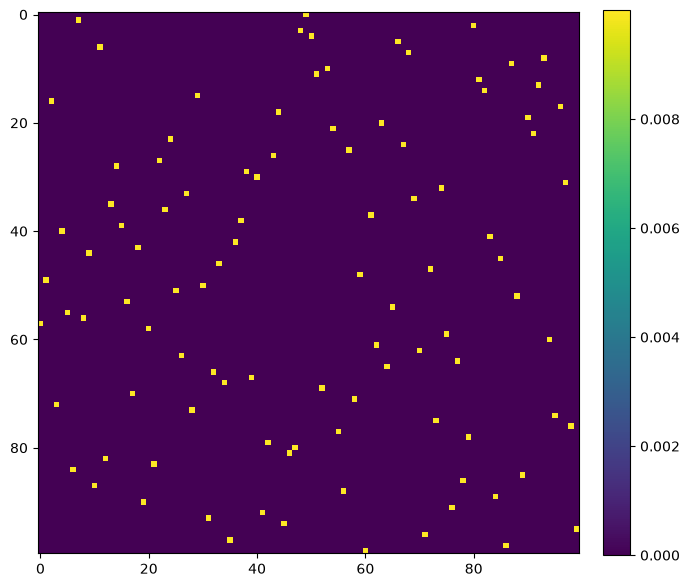

In [102]:
# Compute the batch optimal plan
W = ot.emd(a, b, C)
opt.plot_heatmap(W)